# A1 · Magazzino frigorifero: dai segnali del PLC alla risposta al cliente (PySharp)

Stessa analisi del notebook [C#](A1-magazzino-frigorifero-csharp.ipynb), con la facciata `Interop` della libreria e i grafici di `matplotlib` (PySharp): **stessi numeri**, verificati da un test. Kernel JupyterNet `pysharp` su .NET 11.

## Il caso

Un **magazzino frigorifero** a +2 °C custodisce merce di un cliente (una società alimentare). Il PLC dell'impianto invia a uno storico, ogni minuto, la temperatura della cella, lo stato di porta e sbrinamento, la corrente del compressore, la pressione di aspirazione e la vibrazione. Un contatore invia i kWh ogni ora.

**Chi lavora sui dati.** Il *responsabile qualità* deve poter certificare che la catena del freddo non si è rotta (soglia HACCP +4 °C). Il *manutentore* vuole sapere in anticipo se il compressore sta cedendo. Il *responsabile di stabilimento* deve stimare i consumi di energia della prossima settimana. Il *cliente* chiede: **«la mia merce è stata sempre sotto +4 °C?»**

**I dati sono sintetici**, generati da `generate-data.cs` con un seme: servono a verificare i risultati contro la verità nota (`data/verita.json`), cosa che con dati reali non è mai possibile.

| Passo | Domanda | Strumento |
|---|---|---|
| 1 | I dati sono completi? | qualità dei dati |
| 2 | Qual è la temperatura *vera* quando il sensore tace? | filtro di Kalman con `NaN` ([cap. 6](../../../../refs/timeseries/00-formule-e-libreria/06-kalman.md)) |
| 3 | Quanta energia consumeremo? | seasonal naive, Holt-Winters, MASE ([cap. 3](../../../../refs/timeseries/00-formule-e-libreria/03-riferimenti-e-metriche.md), [5](../../../../refs/timeseries/00-formule-e-libreria/05-smoothing.md)) |
| 4 | Il compressore sta cedendo? | GARCH sulla vibrazione ([cap. 8](../../../../refs/timeseries/00-formule-e-libreria/08-garch.md)) |
| 5 | Come si influenzano temperatura, corrente e pressione? | VAR ([cap. 7](../../../../refs/timeseries/00-formule-e-libreria/07-var.md)) |
| 6 | KPI, dashboard e risposta al cliente | tile, grafici, testo con i numeri |

In [ ]:
import os, math, clr
import matplotlib.pyplot as plt

# La cartella di lavoro deve essere dentro il repository MathemaSharp (scripts/run-notebooks.ps1 parte dalla radice).
root = os.getcwd()
while not os.path.exists(os.path.join(root, "src", "MathemaSharp.slnx")):
    parent = os.path.dirname(root)
    if parent == root:
        raise RuntimeError("Esegui il notebook con la cartella di lavoro dentro il repository MathemaSharp.")
    root = parent
clr.AddReference("D:/Dev/BuildArtifacts/MathemaSharp/bin/MathemaSharp.TimeSeries/release/MathemaSharp.TimeSeries.dll")
from MathemaSharp.TimeSeries.Interop import Forecasts, Metrics, Smoothing, Kalman, Var, Garch

def P(label, values):
    if isinstance(values, (int, float)):
        values = [values]
    print(label + ": " + " ".join("%.6f" % v for v in values))

def num(s):
    return float("nan") if s == "" else float(s)

def read_rows(name):
    f = open(os.path.join(data, name))
    text = f.read()
    f.close()
    return [l.split(",") for l in text.split(chr(10))[1:] if l.strip() != ""], text

data = os.path.join(root, "scenari", "A-magazzino-frigorifero", "data")
rows, _ = read_rows("cella_1min.csv")
temp = [num(r[1]) for r in rows]
current = [num(r[5]) for r in rows]
pressure = [num(r[6]) for r in rows]
vib = [num(r[7]) for r in rows]
limit = 4.0   # soglia HACCP, gradi C

## 1 · Acquisire: i dati sono completi?
Un buco di comunicazione non è un dato a zero: è un dato **assente**. Prima di ogni calcolo si misura quanto manca e dove.

In [ ]:
gaps = []
i = 0
while i < len(temp):
    if not math.isnan(temp[i]):
        i += 1
        continue
    j = i
    while j < len(temp) and math.isnan(temp[j]):
        j += 1
    gaps.append((i, j - i))
    i = j + 1
gap_minutes = sum([g[1] for g in gaps])
P("campioni", len(temp))
P("buchi_n", len(gaps))
P("mancanti_min", gap_minutes)
P("buco_max_min", max([g[1] for g in gaps]))

# Un buco e "sospetto" se la temperatura ai suoi bordi differisce di piu di 1 grado: durante il buco e successo qualcosa.
suspect = [g for g in gaps if g[0] > 0 and g[0] + g[1] < len(temp) and abs(temp[g[0] + g[1]] - temp[g[0] - 1]) > 1.0]
suspect_minutes = sum([g[1] for g in suspect])
P("buchi_sospetti_min", suspect_minutes)

campioni: 4320.000000
buchi_n: 6.000000
mancanti_min: 70.000000
buco_max_min: 20.000000
buchi_sospetti_min: 12.000000


## 2 · Capire la temperatura: il filtro di Kalman
Il sensore ha un rumore noto (σ = 0.08 °C, dal datasheet). Il modello *local level* tratta la temperatura vera come uno stato nascosto che si muove di poco a ogni minuto (varianza $q$); i `NaN` saltano la correzione. La varianza $q$ si sceglie massimizzando la **log-verosimiglianza** su una griglia.

In [ ]:
sensor_variance = 0.08 * 0.08
q_grid = [0.001, 0.003, 0.01, 0.03, 0.1]
log_lik = [Kalman.Filter(Kalman.LocalLevel(q, sensor_variance, temp[0], 1.0), temp).LogLikelihood for q in q_grid]
P("kalman_loglik_grid", log_lik)
q_best = q_grid[log_lik.index(max(log_lik))]
P("kalman_q", q_best)

level = list(Kalman.Filter(Kalman.LocalLevel(q_best, sensor_variance, temp[0], 1.0), temp).FilteredFirstState)
trend = list(Kalman.Filter(Kalman.LocalLinearTrend(q_best, q_best / 10, sensor_variance, temp[0], 0.0, 1.0), temp).FilteredFirstState)

kalman_loglik_grid: -646.218827 2049.143120 2688.980428 2051.162914 435.282661
kalman_q: 0.010000


### Il KPI HACCP: quanti minuti sopra +4 °C?
Quattro risposte allo stesso quesito. **La salita avviene dentro un buco di comunicazione**, quindi nessuno strumento la vede per intero: l'unica risposta onesta è un **intervallo**.

In [ ]:
def above(x):
    return sum([1 for v in x if v > limit])

def runs(x):
    n = 0
    for i in range(len(x)):
        if x[i] > limit and (i == 0 or x[i - 1] <= limit):
            n += 1
    return n

observed = sum([1 for v in temp if (not math.isnan(v)) and v > limit])
P("haccp_osservati_min", observed)
P("haccp_kalman_livello_min", above(level))
P("haccp_kalman_trend_min", above(trend))
P("haccp_escursioni_kalman", runs(level))
P("temp_max_filtrata", max(level))
P("haccp_intervallo_min", [observed, observed + suspect_minutes])

# Verita: la conosce solo il generatore dei dati sintetici, non uno storico reale.
import json
f = open(os.path.join(data, "verita.json"))
truth = json.loads(f.read())
f.close()
truth_minutes = truth["minuti_veri_sopra_soglia"]
P("haccp_verita_min", truth_minutes)
P("haccp_verita_nell_intervallo", 1 if (truth_minutes >= observed and truth_minutes <= observed + suspect_minutes) else 0)

haccp_osservati_min: 7.000000
haccp_kalman_livello_min: 8.000000
haccp_kalman_trend_min: 9.000000
haccp_escursioni_kalman: 1.000000
temp_max_filtrata: 4.494347
haccp_intervallo_min: 7.000000 19.000000
haccp_verita_min: 11.000000
haccp_verita_nell_intervallo: 1.000000


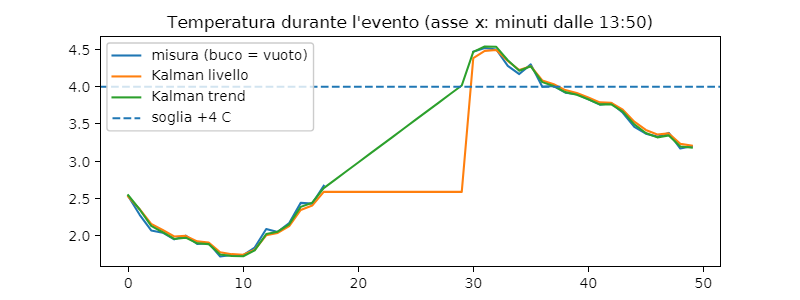

In [ ]:
# L'evento: martedi 15 settembre, dalle 13:50 alle 14:40.
a = 1440 + 13 * 60 + 50
b = 1440 + 14 * 60 + 40
xs = list(range(b - a))
plt.figure(figsize=(8, 3))
plt.plot(xs, temp[a:b], label="misura (buco = vuoto)")
plt.plot(xs, level[a:b], label="Kalman livello")
plt.plot(xs, trend[a:b], label="Kalman trend")
plt.axhline(limit, linestyle="--", label="soglia +4 C")
plt.title("Temperatura durante l'evento (asse x: minuti dalle 13:50)")
plt.legend()
plt.show()

## 3 · Prevedere l'energia della prossima settimana
Sei settimane di kWh orari: cinque di addestramento, l'ultima come **prova a cui il modello non ha mai guardato**. Il confronto è con la MASE rispetto al seasonal naive settimanale ($m=168$): sotto 1 il modello batte il riferimento.

In [ ]:
erows, _ = read_rows("energia_oraria.csv")
kwh = [num(r[1]) for r in erows]
train, test = kwh[:840], kwh[840:]

candidates = [
    ("sn24", list(Forecasts.SeasonalNaive(train, 24, 168))),
    ("sn168", list(Forecasts.SeasonalNaive(train, 168, 168))),
    ("hw24", list(Smoothing.HoltWinters(train, 24, 0.2, 0.01, 0.2, 168, 1.0).Forecast)),
    ("hw168", list(Smoothing.HoltWinters(train, 168, 0.2, 0.01, 0.2, 168, 1.0).Forecast)),
]
for name, fc in candidates:
    P("mase_" + name, Metrics.Mase(test, fc, train, 168))
    P("kwh_sett_" + name, sum(fc))
test_total = sum(test)
P("kwh_sett_reale", test_total)
for name, fc in candidates:
    P("kwh_errore_pct_" + name, 100 * (sum(fc) - test_total) / test_total)
best_name, best_forecast = min(candidates, key=lambda c: Metrics.Mase(test, c[1], train, 168))
print("modello_scelto: " + best_name)

mase_sn24: 1.870867
kwh_sett_sn24: 6478.850000
mase_sn168: 0.918371
kwh_sett_sn168: 7119.510000
mase_hw24: 1.903675
kwh_sett_hw24: 6360.663626
mase_hw168: 0.933787
kwh_sett_hw168: 7414.558830
kwh_sett_reale: 7395.980000
kwh_errore_pct_sn24: -12.400385
kwh_errore_pct_sn168: -3.738112
kwh_errore_pct_hw24: -13.998366
kwh_errore_pct_hw168: 0.251202
modello_scelto: sn168


> **Due criteri, due risposte.** Per il **profilo orario** (MASE) vince il seasonal naive settimanale; per il **totale della settimana** (il budget di energia) è Holt-Winters a sbagliare meno. E con **una sola settimana di prova** la scelta del modello e la sua valutazione coincidono: il risultato è ottimista. La validazione seria ripete la prova su molte origini (*rolling origin*): è fra le teorie del libro non ancora implementate.

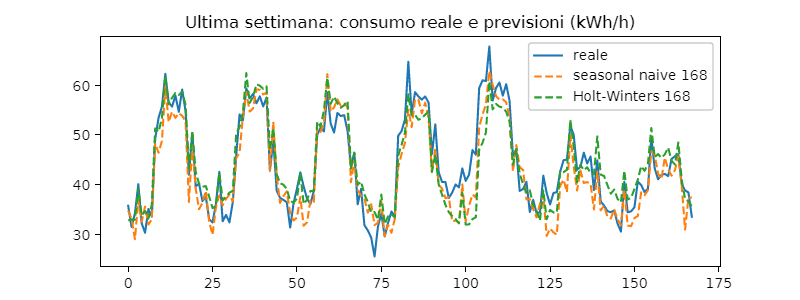

In [ ]:
plt.figure(figsize=(8, 3))
plt.plot(range(168), test, label="reale")
plt.plot(range(168), candidates[1][1], linestyle="--", label="seasonal naive 168")
plt.plot(range(168), candidates[3][1], linestyle="--", label="Holt-Winters 168")
plt.title("Ultima settimana: consumo reale e previsioni (kWh/h)")
plt.legend()
plt.show()

## 4 · Il compressore sta cedendo? La volatilità della vibrazione
La vibrazione dipende dallo stato del compressore (acceso/spento). Tolto il livello di ciascuno stato, restano shock la cui **varianza** dice quanto il compressore è "inquieto". Il GARCH si addestra sulle **prime 48 ore** (comportamento normale) e poi si legge la volatilità condizionale sulle 24 ore successive.

In [ ]:
on = [c > 10 for c in current]

def mean_state(state):
    s = 0.0
    n = 0
    for i in range(2880):
        if on[i] == state:
            s += vib[i]
            n += 1
    return s / n

m_on = mean_state(True)
m_off = mean_state(False)
P("vib_livello_on_off", [m_on, m_off])
residual = [v - (m_on if on[i] else m_off) for i, v in enumerate(vib)]

garch = Garch.FitVarianceTargeting(residual[:2880])
P("garch_fit", [garch.Omega, garch.Alpha, garch.Beta])
sigma_bar = math.sqrt(garch.UnconditionalVariance)
P("garch_sigma_base", sigma_bar)
sigma = [math.sqrt(v) for v in garch.ConditionalVariances(residual)]
alarm = [s > 1.5 * sigma_bar for s in sigma]

def rate(first, last):
    return sum([1 for i in range(first, last) if alarm[i]]) / (last - first)

P("allarme_giorno1", rate(0, 1440))
P("allarme_giorno2", rate(1440, 2880))
P("allarme_giorno3", rate(2880, 4320))

# Allarme sostenuto: almeno 8 minuti sopra soglia nell'ultima ora (finestra mobile di 60 minuti).
first_alarm = -1
window = 0
for i in range(len(alarm)):
    if alarm[i]:
        window += 1
    if i >= 60 and alarm[i - 60]:
        window -= 1
    if window >= 8 and first_alarm < 0:
        first_alarm = i
P("allarme_primo_minuto", first_alarm)
P("allarme_ritardo_min", first_alarm - 2880)   # il cambiamento vero e al minuto 2880 (48 h): negativo = falso allarme

vib_livello_on_off: 2.599607 0.400610
garch_fit: 0.001890 0.082975 0.809350
garch_sigma_base: 0.132491
allarme_giorno1: 0.004861
allarme_giorno2: 0.002083
allarme_giorno3: 0.227083
allarme_primo_minuto: 2951.000000
allarme_ritardo_min: 71.000000


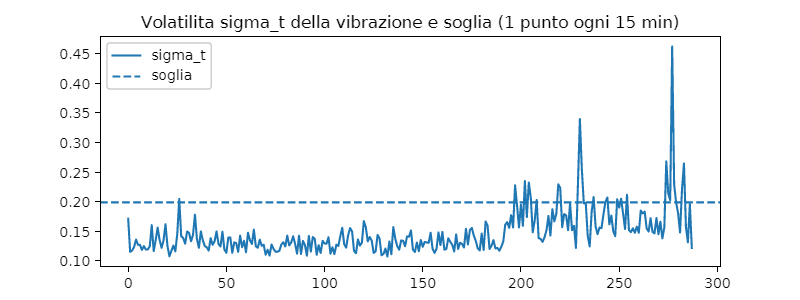

In [ ]:
plt.figure(figsize=(8, 3))
plt.plot(range(0, len(sigma) // 15), [sigma[i * 15] for i in range(len(sigma) // 15)], label="sigma_t")
plt.axhline(1.5 * sigma_bar, linestyle="--", label="soglia")
plt.title("Volatilita sigma_t della vibrazione e soglia (1 punto ogni 15 min)")
plt.legend()
plt.show()

## 5 · Segnali accoppiati: VAR
Medie su 5 minuti di temperatura (filtrata), corrente e pressione. Il VAR(1) risponde: *quanto la corrente di adesso predice la temperatura fra cinque minuti?*

In [ ]:
step = 5
n5 = len(temp) // step
flat = []
for k in range(n5):
    st = 0.0
    sc = 0.0
    sp = 0.0
    for j in range(step):
        st += level[k * step + j]
        sc += current[k * step + j]
        sp += pressure[k * step + j]
    flat.extend([st / step, sc / step, sp / step])
var3 = Var.Fit(flat, n5, 3, 1)
P("var_a1", list(Var.Coefficient(var3, 1)))

var_a1: 0.841806 -0.032525 -0.068756 9.057558 0.728416 3.997443 -0.463599 -0.038371 -0.227008


Lettura di $A_1$ (righe = equazioni, colonne = temperatura, corrente, pressione al passo precedente): **temperatura ← corrente** è negativa (compressore acceso ⇒ la cella si raffredda); **corrente ← temperatura** è fortemente positiva (cella calda ⇒ il termostato accende il compressore). Il VAR ritrova, dai soli dati, la logica del termostato.

## 6 · Comunicare: KPI, dashboard e risposta al cliente

In [ ]:
STATUS = {"ok": "&#10003; nella norma", "warn": "&#9650; attenzione", "alarm": "&#10006; allarme", "": ""}

def tiles(items):
    html = '<div style="display:grid;grid-template-columns:repeat(auto-fit,minmax(170px,1fr));gap:8px;font-family:system-ui,sans-serif">'
    for label, value, note, status in items:
        html += '<div style="background:#fcfcfb;border:1px solid #e4e3df;border-radius:8px;padding:10px 12px">'
        html += '<div style="font-size:12px;color:#52514e">' + label + '</div>'
        html += '<div style="font-size:26px;font-weight:600;color:#0b0b0b;line-height:1.2">' + value + '</div>'
        html += '<div style="font-size:12px;color:#52514e">' + note + '</div>'
        if STATUS[status] != "":
            html += '<div style="font-size:12px;font-weight:600;color:#0b0b0b;margin-top:2px">' + STATUS[status] + '</div>'
        html += '</div>'
    display_html(html + '</div>')

def quote(title, text):
    display_html('<div style="background:#fcfcfb;border-left:4px solid #2a78d6;padding:10px 14px;margin:8px 0;font-family:system-ui,sans-serif;color:#0b0b0b"><div style="font-size:12px;color:#52514e">' + title + '</div><div style="font-size:14px">' + text + '</div></div>')

energy_next = sum(best_forecast)
alarm_day3 = rate(2880, 4320)
day1 = rate(0, 1440)
upper = observed + suspect_minutes
mase_best = Metrics.Mase(test, best_forecast, train, 168)
energy_error = 100 * (energy_next - test_total) / test_total

tiles([
    ("Tempo sopra +4 &deg;C", "%d&ndash;%d min" % (observed, upper), "minimo osservato &ndash; massimo non escludibile", "warn"),
    ("Escursioni HACCP", "%d" % runs(level), "temperatura massima stimata %.1f &deg;C" % max(level), "warn"),
    ("Dati mancanti", "%.1f %%" % (100.0 * gap_minutes / len(temp)), "%d buchi, il pi&ugrave; lungo %d min" % (len(gaps), max([g[1] for g in gaps])), "ok"),
    ("Energia prossima settimana", "%.0f kWh" % energy_next, "modello %s, MASE %.2f; sul totale %+.1f %% nella settimana di prova" % (best_name, mase_best, energy_error), "ok"),
    ("Vibrazione compressore", "%.0f %% allarme" % (100 * alarm_day3), "ultime 24 h, contro %.1f %% il primo giorno; primo allarme %d min dopo il cambio" % (100 * day1, first_alarm - 2880), "alarm" if alarm_day3 > 0.2 else "ok"),
])

Tempo sopra +4 °C 7–19 min minimo osservato – massimo non escludibile ▲ attenzione Escursioni HACCP 1 temperatura massima stimata 4.5 °C ▲ attenzione Dati mancanti 1.6 % 6 buchi, il più lungo 20 min ✓ nella norma Energia prossima settimana 7120 kWh modello sn168, MASE 0.92; sul totale -3.7 % nella settimana di prova ✓ nella norma Vibrazione compressore 23 % allarme ultime 24 h, contro 0.5 % il primo giorno; primo allarme 71 min dopo il cambio ✖ allarme

Risposta al cliente: la mia merce e stata sempre sotto +4 C? Nelle 72 ore dal 14 al 16 settembre la temperatura della cella e stata osservata sopra +4 C per almeno 7 minuti, in 1 escursione, con un massimo stimato di 4.5 C (martedi pomeriggio). In 12 minuti il sensore non ha comunicato e la temperatura ai bordi del buco differiva di oltre 1 C: non possiamo escludere altri minuti sopra soglia, per un massimo di 19. Per questo la nostra risposta non e sempre sotto +4 C, ma da 7 a 19 minuti sopra soglia in un'unica escursione; proponiamo di verificare la porta della cella e il gateway di comunicazione.

Nota per la manutenzione La volatilita della vibrazione del compressore e oltre soglia nel 23 % dell'ultimo giorno (contro il 0.5 % del primo). L'allarme sostenuto e scattato 71 minuti dopo l'inizio del cambiamento: consigliato un controllo del cuscinetto.

In [ ]:
answer = ("Nelle 72 ore dal 14 al 16 settembre la temperatura della cella e stata osservata sopra +4 C per almeno %d minuti, in %d escursione, con un massimo stimato di %.1f C (martedi pomeriggio). " % (observed, runs(level), max(level))
    + "In %d minuti il sensore non ha comunicato e la temperatura ai bordi del buco differiva di oltre 1 C: non possiamo escludere altri minuti sopra soglia, per un massimo di %d. " % (suspect_minutes, upper)
    + "Per questo la nostra risposta non e sempre sotto +4 C, ma da %d a %d minuti sopra soglia in un'unica escursione; proponiamo di verificare la porta della cella e il gateway di comunicazione." % (observed, upper))
quote("Risposta al cliente: la mia merce e stata sempre sotto +4 C?", answer)

maintenance = ("La volatilita della vibrazione del compressore e oltre soglia nel %.0f %% dell'ultimo giorno (contro il %.1f %% del primo). " % (100 * alarm_day3, 100 * day1)
    + "L'allarme sostenuto e scattato %d minuti dopo l'inizio del cambiamento: consigliato un controllo del cuscinetto." % (first_alarm - 2880))
quote("Nota per la manutenzione", maintenance)

## Cosa abbiamo imparato
- **Un buco nei dati è un'informazione**: il KPI HACCP si dà come intervallo, e la verità nota (11 minuti) cade dentro.
- **Il Kalman fa il suo lavoro ma non indovina**: non vede una salita avvenuta interamente nel buco, né con il solo livello né con il trend.
- **GARCH come campanello**: non dice *cosa* sta cedendo, dice che il comportamento è cambiato; l'allarme non coincide con il cambiamento (*change time is not alarm time*).
- **Stessi numeri in C# e PySharp**: stessa libreria, stessa risposta, linguaggio a scelta di chi lavora sull'impianto.